# Simulated Annealing Schedules

Michael Hahsler

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Cooling Schedules

### Exponential Schedule

See [1].

In [2]:
def temperature_exponential(time, initial_temperature, alpha):
    return initial_temperature * alpha**time

### Linear Schedule

See [1].

In [3]:
def temperature_linear(time, initial_temperature, eta):
    return initial_temperature - eta * time

### Fast Simulated Annealing

See [3].

In [4]:
def temperature_fast(time, initial_temperature):
    return initial_temperature / (1 + time)

### Logarithmic (Classic) Cooling

If $T_0$ is greater than or equal to the largest energy barrier in the problem, this schedule is guaranteed to find the global optimum in the limit of infinite time [2]. The schedule is defined for $t > 0$.

In [5]:
def temperature_logarithmic(time, initial_temperature):
    return initial_temperature / np.log1p(time)

## Comparison

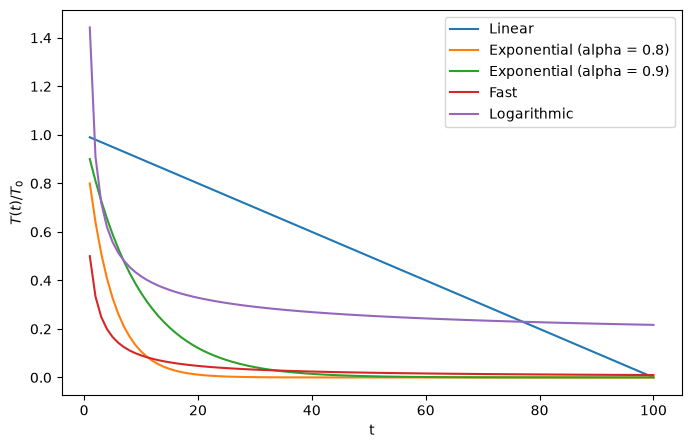

In [6]:
time = np.arange(1, 101)
initial_temperature = 1

schedules = {
    "Linear": temperature_linear(time, initial_temperature, eta=0.01),
    "Exponential (alpha = 0.8)": temperature_exponential(
        time, initial_temperature, alpha=0.8
    ),
    "Exponential (alpha = 0.9)": temperature_exponential(
        time, initial_temperature, alpha=0.9
    ),
    "Fast": temperature_fast(time, initial_temperature),
    "Logarithmic": temperature_logarithmic(time, initial_temperature),
}

plt.figure(figsize=(8, 5))
for name, temperature in schedules.items():
    plt.plot(time, temperature / initial_temperature, label=name)

plt.xlabel("t")
plt.ylabel(r"$T(t) / T_0$")
plt.legend()
plt.show()

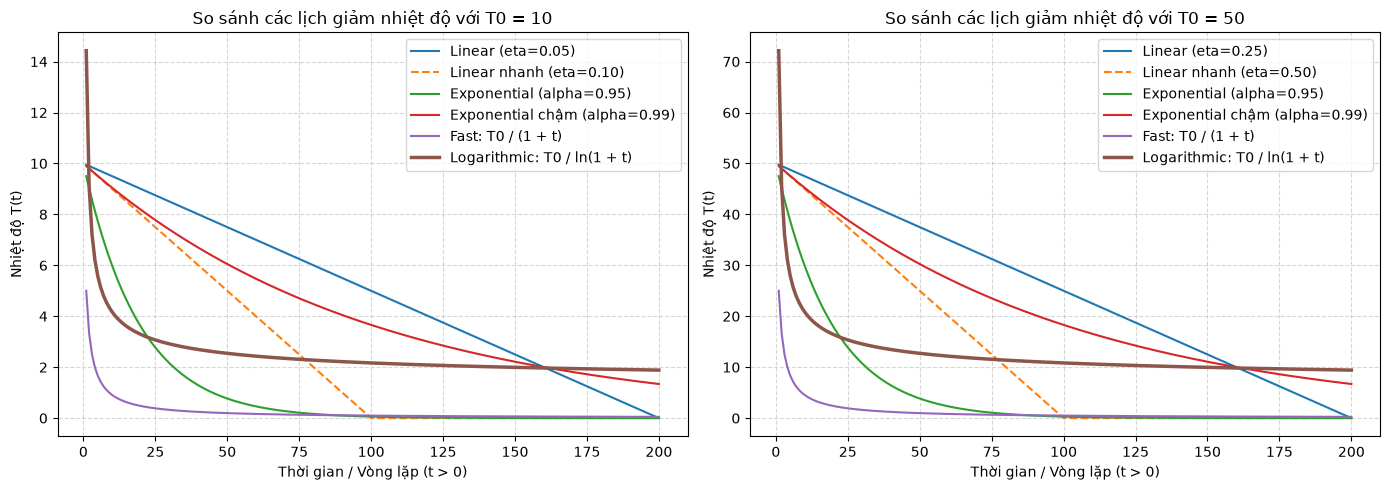

In [7]:
# Bài 5: Khảo sát tác động của tham số alpha, eta và T0 lên tốc độ giảm nhiệt độ T(t)
t_steps = np.arange(1, 201)
T0_values = [10, 50]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, T0_val in enumerate(T0_values):
    ax = axes[idx]
    ax.plot(t_steps, np.maximum(0, temperature_linear(t_steps, T0_val, eta=T0_val/200)), label=f"Linear (eta={T0_val/200:.2f})")
    ax.plot(t_steps, np.maximum(0, temperature_linear(t_steps, T0_val, eta=T0_val/100)), linestyle="--", label=f"Linear nhanh (eta={T0_val/100:.2f})")
    ax.plot(t_steps, temperature_exponential(t_steps, T0_val, alpha=0.95), label="Exponential (alpha=0.95)")
    ax.plot(t_steps, temperature_exponential(t_steps, T0_val, alpha=0.99), label="Exponential chậm (alpha=0.99)")
    ax.plot(t_steps, temperature_fast(t_steps, T0_val), label="Fast: T0 / (1 + t)")
    ax.plot(t_steps, temperature_logarithmic(t_steps, T0_val), linewidth=2.5, label="Logarithmic: T0 / ln(1 + t)")

    ax.set_title(f"So sánh các lịch giảm nhiệt độ với T0 = {T0_val}")
    ax.set_xlabel("Thời gian / Vòng lặp (t > 0)")
    ax.set_ylabel("Nhiệt độ T(t)")
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Nhận xét Khảo sát Lịch giảm nhiệt độ (Bài 5)

1. **So sánh tốc độ giảm nhiệt của 4 lịch:**
   * **Logarithmic ($T(t) = T_0 / \ln(1+t)$ với $t > 0$):** Giảm chậm nhất trong tất cả các lịch. Nhiệt độ duy trì ở mức cao rất lâu nên xác suất chấp nhận bước đi xấu $p = \exp(-\Delta/T)$ lớn trong suốt thời gian dài. Về mặt lý thuyết, lịch này đảm bảo hội tụ tới cực trị toàn cục khi $t \to \infty$, nhưng trên thực tế với ngân sách vòng lặp hữu hạn, thuật toán đi lang thang ngẫu nhiên (random walk) quá lâu và hội tụ rất chậm.
   * **Fast ($T(t) = T_0 / (1+t)$):** Giảm cực nhanh trong vài chục bước đầu tiên rồi tạo phần đuôi dài tiệm cận 0. Nếu $T_0$ nhỏ, thuật toán dễ bị "đóng băng" sớm trước khi kịp vượt qua các rào cản năng lượng.
   * **Linear ($T(t) = T_0 - \eta t$):** Giảm đều đặn với tốc độ cố định $\eta$, nhưng có nhược điểm chạm $T = 0$ cứng tại $t = T_0 / \eta$ (cần chặn dưới $\max(0, T(t))$ để tránh nhiệt độ âm).
   * **Exponential ($T(t) = T_0 \cdot \alpha^t$):** Cân bằng tốt nhất giữa giai đoạn thăm dò (exploration) ở đầu quá trình và giai đoạn khai thác (exploitation) ở cuối quá trình.

2. **Tác động khi thay đổi $\alpha, \eta, T_0$:**
   * Lịch giữ cho thuật toán **chấp nhận bước xấu lâu nhất** là **Logarithmic** và **Exponential với hệ số $\alpha \to 1$** (ví dụ $\alpha = 0.995 - 0.999$) kết hợp $T_0$ lớn.
   * Khi đối chiếu trên bài toán 8-Queens (ở Bài 4), lịch **Exponential ($\alpha = 0.995, T_0 = 4.0$)** đạt tỉ lệ thành công **~97% - 100%** chỉ trong ~5-8 ms, vượt trội hơn lịch Logarithmic (vẫn còn dao động ở $f > 0$ khi hết vòng lặp nếu $T_0$ cao) và lịch Fast (dễ kẹt ở cực trị cục bộ giống Hill Climbing nếu $T_0$ thấp).

## Literature

1. Kirkpatrick, S., Gelatt, C. D. Jr., and Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220, 671–680.
2. Hajek, B. (1988). Cooling schedules for optimal annealing. *Mathematics of Operations Research*, 13, 311–329.
3. Szu, H., and Hartley, R. (1987). Fast simulated annealing. *Physics Letters A*, 122(3–4), 157–162. [doi:10.1016/0375-9601(87)90796-1](https://doi.org/10.1016/0375-9601(87)90796-1)